# ÖDEV: Derin Öğrenme ve Evrişimsel Sinir Ağlarının (CNN) Temel Yapısının İncelenmesi

- **Öğrenci:** Melike Yetmen
- **Öğrenci No:** 02230224059
- **Bölüm / Sınıf:** Yazılım Mühendisliği — 4. Sınıf
- **Ders:** Bilgisayar Görmesi / YMG-3
- **Programlama Dili ve Kütüphane:** Python, TensorFlow / Keras
- **Veri Seti:** Fashion-MNIST

---

## 1. Ödevin Amacı
Bu çalışmada derin öğrenme modellerinin ve özellikle **Evrişimsel Sinir Ağlarının (CNN)** çalışma prensipleri basitten başlayarak incelenmektedir. Yalnızca sınıflandırma yapan bir model eğitmek yerine; **Konvolüsyon (Conv2D)**, **Filtre (Kernel) ve Ağırlıklar**, **Max Pooling**, **ReLU**, **Flatten**, **Dense (Tam Bağlantılı)** katmanlar ile **Softmax** çıkış fonksiyonunun görevleri, giriş-çıkış boyut dönüşümleri ve hiperparametre değişimlerinin (8 vs 16 filtre) model başarısına etkisi hem teorik hem uygulamalı olarak analiz edilmiştir.

## 2. Bölüm: Temel Kavramların İncelenmesi

### Soru 1. Derin öğrenme nedir?
- **Derin Öğrenme:** Yapay zekânın bir alt alanı olan makine öğrenmesinin, insan beynindeki sinir ağlarından esinlenen çok katmanlı yapay sinir ağlarını kullanarak veriden doğrudan hiyerarşik temsiller öğrendiği yöntemler bütünüdür.
- **Makine Öğrenmesi ile Derin Öğrenme Arasındaki Fark:** Klasik makine öğrenmesinde (ör. SVM, Karar Ağaçları, Lojistik Regresyon) ham veriden anlamlı özniteliklerin çıkarılması (*feature extraction*) çoğunlukla alan uzmanları tarafından elle yapılır ve büyük miktarda veriyle ölçeklenmesi sınırlıdır. Derin öğrenmede ise model, ham piksel gibi düşük seviye verilerden başlayarak en uygun öznitelikleri katmanlar boyunca **otomatik olarak** öğrenir; veri ve donanım (GPU) arttıkça başarısı klasik yöntemlerin üzerine çıkar.
- **Yapay Sinir Ağları Nasıl Çalışır?** Her yapay nöron; aldığı girdileri öğrenebilir ağırlıklarla (*weights*) çarpar, bir sapma (*bias*) değeri ekler ve sonucu doğrusal olmayan bir aktivasyon fonksiyonundan geçirir. Eğitim sürecinde veri ağdan ileri doğru geçirilerek tahmin üretilir (*forward propagation*), tahmin ile gerçek değer arasındaki hata bir kayıp (*loss*) fonksiyonuyla ölçülür ve **geri yayılım (*backpropagation*)** ile gradyan inişi algoritması kullanılarak ağırlıklar hatayı azaltacak yönde güncellenir.
- **Neden Birden Fazla Katmandan Oluşur?** Tek katmanlı yapılar yalnızca doğrusal olarak ayrılabilen basit ilişkileri öğrenebilir. Birden fazla katman kullanıldığında ağ **hiyerarşik bir temsil** oluşturur: örneğin bir görüntü sınıflandırma ağında ilk katmanlar kenar, çizgi ve renk geçişlerini; orta katmanlar doku ve geometrik şekilleri; son katmanlar ise nesne parçalarını ve bütün nesneyi tanır.

---

### Soru 2. Konvolüsyon nedir?
- **Görüntü Üzerinde Konvolüsyon İşlemi:** Görüntü piksellerden oluşan sayısal bir matristir. Küçük boyutlu bir ağırlık matrisi (filtre/kernel), giriş görüntüsü üzerinde soldan sağa ve yukarıdan aşağıya kaydırılır. Her konumda filtrenin elemanları ile görüntünün altındaki piksel değerleri eleman bazında çarpılıp toplanır (ve bias eklenir); elde edilen tek sayı çıkış öznitelik haritasında (*feature map*) ilgili konuma yazılır.
- **Kernel (Filtre) Nedir?** Görüntüdeki belirli bir görsel örüntüyü (yatay kenar, dikey kenar, köşe, doku vb.) tespit etmek için kullanılan ve eğitim sırasında değerleri öğrenilen küçük boyutlu ağırlık matrisidir.
- **3×3 Boyutundaki Bir Filtrenin Kaç Ağırlık Parametresi Vardır?**
  - `3 × 3 = 9` adet ağırlık (*weight*) parametresi vardır (tek kanallı gri seviye girdi için `+1` bias ile toplam `10` öğrenilebilir parametre; genel olarak $C_{\text{in}}$ kanallı bir giriş için $3 \times 3 \times C_{\text{in}}$ ağırlık ve `1` bias bulunur).
- **Filtre Görüntü Üzerinde Hareket Ederken Ne Yapar?** Yerel komşuluktaki piksellerle nokta çarpımı (*dot product*) hesaplayarak o bölgede aradığı görsel örüntünün ne kadar güçlü bulunduğunu ölçer; örüntüyle eşleşen bölgelerde yüksek, eşleşmeyen bölgelerde düşük aktivasyon üretir.
- **Bir CNN'de Neden Birden Fazla Filtre Kullanılır?** Tek bir filtre yalnızca tek tip bir örüntüyü (örneğin sadece dikey kenarları) yakalayabilir. Birden fazla filtre kullanıldığında her filtre farklı bir görsel özelliği (yatay kenar, eğri, köşe, doku vb.) öğrenerek görüntünün zengin ve çok boyutlu bir temsilini çıkarır.

---

### Soru 3. Pooling nedir?
- **Max Pooling İşleminin Amacı:** Konvolüsyon katmanından çıkan öznitelik haritalarının uzamsal boyutlarını (yükseklik ve genişlik) küçültmek (*downsampling*), sonraki katmanlardaki parametre sayısını ve hesaplama yükünü azaltmak, aşırı öğrenmeyi (*overfitting*) sınırlamak ve nesnelerin görüntü içindeki küçük konum kaymalarına karşı dayanıklılık (*translation invariance*) kazandırmaktır.
- **2×2 Max Pooling Nasıl Çalışır?** Görüntü veya öznitelik haritası üzerinde 2×2 boyutunda bir pencere (genellikle `stride=2` ile örtüşmeden) gezdirilir ve her 2×2 bölgedeki **en büyük piksel değeri** seçilerek çıkış matrisine yazılır.
- **Giriş Görüntüsünün Boyutunu Nasıl Değiştirir?** `pool_size=(2, 2)` ve `strides=2` uygulandığında girişin yüksekliği ve genişliği yarıya iner ($H \times W \rightarrow \lfloor H/2 \rfloor \times \lfloor W/2 \rfloor$), böylece uzamsal alan dörtte birine düşer; kanal (filtre) sayısı ise değişmeden korunur.

---

### Soru 4. Aktivasyon fonksiyonları
- **Aktivasyon Fonksiyonları Neden Kullanılır?** Katmanlara **doğrusal olmama (*non-linearity*)** kazandırır. Eğer aktivasyon fonksiyonu kullanılmazsa ardışık tüm katmanlar matematiksel olarak tek bir doğrusal matris çarpımına indirgenir ve ağ karmaşık örüntüleri öğrenemez.
- **ReLU (Rectified Linear Unit) Nasıl Çalışır?** $f(x) = \max(0, x)$ kuralıyla çalışır; negatif girişleri `0`'a sıfırlar, sıfır ve pozitif girişleri olduğu gibi geçirir. Hesaplaması çok hızlıdır ve derin ağlarda gradyan kaybolması (*vanishing gradient*) sorununu azaltır.
- **Softmax Fonksiyonu Ne İşe Yarar?** Çok sınıflı sınıflandırma problemlerinde ağın son katmanından çıkan ham skorları (*logits*) $\text{Softmax}(z_i) = \frac{e^{z_i}}{\sum_j e^{z_j}}$ formülüyle `0` ile `1` arasında ve toplamları `1` olan bir olasılık dağılımına dönüştürür.
- **ReLU ile Softmax Arasındaki Temel Fark Nedir?** ReLU gizli katmanlarda kullanılır, her elemana bağımsız uygulanır ve üst sınırı yoktur (`[0, ∞)`). Softmax ise genellikle çıkış katmanında kullanılır, tüm sınıfların skorlarını birbirine bağlı biçimde normalize ederek toplamı `1` olan olasılıklar (`(0, 1)`) üretir.

---

### Soru 5. Dense katman
- **Dense (Tam Bağlantılı) Katman Nedir?** Bir önceki katmandaki her nöronun, mevcut katmandaki tüm nöronlara ayrı ayrı ağırlıklarla bağlandığı klasik yapay sinir ağı katmanıdır.
- **Flatten Katmanının Görevi Nedir?** Konvolüsyon ve Pooling katmanlarından gelen çok boyutlu tensörü (örneğin `(5, 5, 16)`) Dense katmanının kabul edebileceği tek boyutlu vektöre (`400` elemanlı) dönüştürür.
- **CNN Mimarisinde Dense Katmanlar Neden Kullanılır?** Konvolüsyon ve Pooling katmanları görüntüdeki yerel ve hiyerarşik görsel öznitelikleri çıkarır; Dense katmanlar ise çıkarılan tüm bu öznitelikleri global olarak birleştirip yorumlayarak nihai sınıflandırma kararını verir.

## 3. Bölüm: Konvolüsyon İşleminin Kodlanması
Aşağıdaki kodda 3×3 boyutunda 16 filtreye sahip, `relu` aktivasyonlu ve `he_normal` ağırlık başlatıcılı bir `Conv2D` katmanı oluşturularak `(1, 128, 128, 1)` boyutundaki örnek görüntü tensörü üzerinde çalıştırılmaktadır.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Rastgelelik kontrolü
tf.keras.utils.set_random_seed(42)

# 3x3 boyutunda 16 filtreli konvolüsyon katmanı
conv = tf.keras.layers.Conv2D(
    filters=16,
    kernel_size=(3, 3),
    activation='relu',
    kernel_initializer='he_normal'
)

# Örnek giriş görüntüsü
dummy_input = tf.random.normal((1, 128, 128, 1))

# Konvolüsyon işlemi
output = conv(dummy_input)

# Ağırlıkları al
weights, biases = conv.get_weights()

print("Giriş boyutu:", dummy_input.shape)
print("Çıkış boyutu:", output.shape)
print("Filtre ağırlıklarının boyutu:", weights.shape)
print("Bias boyutu:", biases.shape)

# İlk filtrenin ağırlıkları
print("İlk filtre:")
print(weights[:, :, 0, 0])

Giriş boyutu: (1, 128, 128, 1)
Çıkış boyutu: (1, 126, 126, 16)
Filtre ağırlıklarının boyutu: (3, 3, 1, 16)
Bias boyutu: (16,)
İlk filtre:
[[-0.25283593  0.12861036 -0.75786656]
 [-0.21681367 -0.15182823 -0.702172  ]
 [ 0.23038778  0.76512676 -0.74278826]]


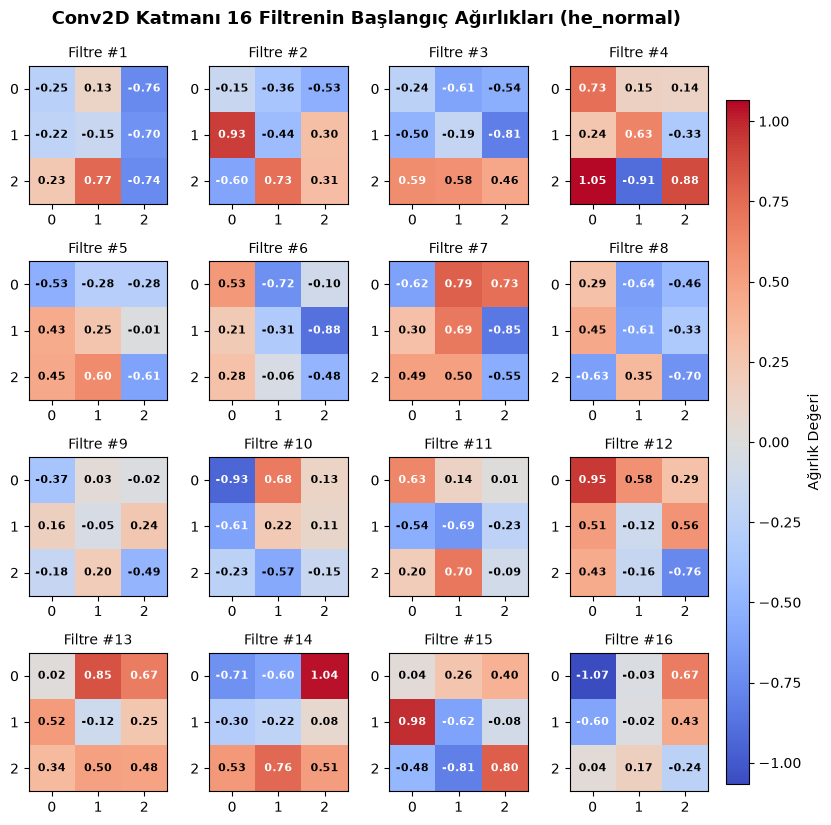

In [2]:
# Bütün filtrelerin (16 adet 3x3) başlangıç ağırlıklarının görselleştirilmesi
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
vmax = float(np.max(np.abs(weights)))

for idx, ax in enumerate(axes.flat):
    kernel = weights[:, :, 0, idx]
    im = ax.imshow(kernel, cmap='coolwarm', vmin=-vmax, vmax=vmax)
    ax.set_title(f'Filtre #{idx + 1}', fontsize=10)
    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])
    for r in range(3):
        for c in range(3):
            val = kernel[r, c]
            txt_color = 'white' if abs(val) > vmax * 0.55 else 'black'
            ax.text(c, r, f'{val:.2f}', ha='center', va='center', fontsize=8, color=txt_color, fontweight='bold')

fig.suptitle('Conv2D Katmanı 16 Filtrenin Başlangıç Ağırlıkları (he_normal)', fontsize=13, fontweight='bold', y=0.98)
fig.subplots_adjust(right=0.88, top=0.92, hspace=0.38, wspace=0.30)
cbar_ax = fig.add_axes([0.90, 0.12, 0.025, 0.76])
fig.colorbar(im, cax=cbar_ax, label='Ağırlık Değeri')
plt.show()

### Bölüm 3 Çalışma Sorularının Cevapları
1. **16 filtre ne anlama gelmektedir?** Katmanın aynı giriş görüntüsü üzerinde birbirinden bağımsız **16 farklı öznitelik dedektörü** öğreneceği ve çıkışta 16 ayrı öznitelik haritası (kanal) üreteceği anlamına gelir.
2. **Her filtrenin boyutu nedir?** Giriş görüntüsü tek kanallı (gri seviye) olduğu için her filtre **`3 × 3 × 1`** boyutundadır (9 ağırlık + 1 bias = 10 parametre).
3. **`weights` değişkeninin boyutu `(3, 3, 1, 16)` neyi ifade eder?** Keras `Conv2D` ağırlık tensörü `(kernel_height, kernel_width, input_channels, output_filters)` formatındadır: 3×3 filtre boyutu, 1 giriş kanalı ve 16 çıkış filtresi (toplam $3 \times 3 \times 1 \times 16 = 144$ ağırlık).
4. **`biases` değişkeninin boyutu `(16,)` neyi ifade eder?** 16 filtrenin her biri için konvolüsyon toplamına eklenen 1 adet sapma (*bias*) değeri bulunduğunu gösterir (toplam 16 bias).
5. **Giriş boyutu `128×128` iken çıkış boyutu neden `(1, 126, 126, 16)` olmuştur?** Varsayılan dolgu ayarı `padding='valid'` ve adım `strides=(1, 1)` olduğu için `3×3` filtre görüntünün kenarlarından taşmadan yerleştirilir. Çıkış boyutu $\lfloor (128 - 3) / 1 \rfloor + 1 = 126$ olarak hesaplanır; yani kenarlardan 1'er piksel kayıpla `126×126` boyutuna düşer.
6. **`kernel_initializer='he_normal'` ne anlama gelmektedir?** ReLU aktivasyonu kullanan katmanlar için He ve ark. tarafından önerilen ağırlık başlatma yöntemidir. Ağırlıkları ortalaması `0`, standart sapması $\sqrt{2 / n_{\text{in}}}$ olan kesik normal dağılımdan rastgele seçerek derin ağlarda aktivasyonların sönmesini veya patlamasını engeller.

## 4. Bölüm: Pooling İşleminin İncelenmesi

In [3]:
# Örnek giriş matrisi
input_data = tf.constant([
    [[1., 3., 2., 4.],
     [5., 6., 1., 2.],
     [7., 2., 8., 3.],
     [4., 1., 5., 9.]]
])

# Boyutları düzenle: Batch, Height, Width, Channels
input_data = tf.reshape(input_data, (1, 4, 4, 1))

pool = tf.keras.layers.MaxPooling2D(
    pool_size=(2, 2),
    strides=2
)

output = pool(input_data)

print("Giriş boyutu:", input_data.shape)
print("Giriş:")
print(input_data.numpy()[0, :, :, 0])
print("Çıkış boyutu:", output.shape)
print("Pooling sonucu:")
print(output.numpy()[0, :, :, 0])

Giriş boyutu: (1, 4, 4, 1)
Giriş:
[[1. 3. 2. 4.]
 [5. 6. 1. 2.]
 [7. 2. 8. 3.]
 [4. 1. 5. 9.]]
Çıkış boyutu: (1, 2, 2, 1)
Pooling sonucu:
[[6. 4.]
 [7. 9.]]


### Bölüm 4 Çalışma Sorularının Cevapları
1. **Elle Hesaplanan 2×2 Bölgelerin Maksimum Değerleri:**
   - Sol-Üst bölge `[[1, 3], [5, 6]]` → En büyük: **6**
   - Sağ-Üst bölge `[[2, 4], [1, 2]]` → En büyük: **4**
   - Sol-Alt bölge `[[7, 2], [4, 1]]` → En büyük: **7**
   - Sağ-Alt bölge `[[8, 3], [5, 9]]` → En büyük: **9**
2. **Karşılaştırma:** Elle hesaplanan `[[6., 4.], [7., 9.]]` sonucu, `MaxPooling2D` katmanının ürettiği çıktı ile **birebir aynıdır**.
3. **Giriş ve Çıkış Boyutlarının Açıklaması:** Giriş tensörü `(1, 4, 4, 1)` (1 örnek, 4×4 uzamsal boyut, 1 kanal) şeklindedir. `pool_size=(2, 2)` ve `strides=2` ile her 2×2 blok tek bir değere indirgendiğinden çıkış `(1, 2, 2, 1)` olur; yükseklik ve genişlik yarıya inerken batch ve kanal sayısı değişmez.
4. **Max Pooling'in CNN Açısından Avantajları:** En belirgin (baskın) öznitelik aktivasyonlarını koruyarak boyutu %75 oranında küçültür, hesaplama ve bellek maliyetini düşürür, aşırı öğrenmeyi azaltır ve küçük kaymalara/dönüşümlere karşı modelin genelleme yeteneğini artırır.

## 5. Bölüm: ReLU ve Softmax Fonksiyonlarının İncelenmesi
### A. ReLU

In [4]:
x = tf.constant([-5., -2., -1., 0., 2., 4., 6.])
relu = tf.keras.layers.ReLU()
y = relu(x)

print("Giriş:", x.numpy())
print("ReLU çıkışı:", y.numpy())

Giriş: [-5. -2. -1.  0.  2.  4.  6.]
ReLU çıkışı: [0. 0. 0. 0. 2. 4. 6.]


- **Negatif değerler neden sıfırlanmıştır?** ReLU fonksiyonu $f(x) = \max(0, x)$ tanımı gereği sıfırın altındaki tüm değerleri `0`'a çeker. Böylece yalnızca eşiği aşan (aktif) nöronlar bir sonraki katmana sinyal taşır (*sparsity* / seyreklik sağlar).
- **Pozitif değerler neden korunmuştur?** $x > 0$ için türevin sabit `1` olması sayesinde sinyalin zayıflamadan ileri aktarılmasını ve geri yayılımda gradyan kaybolmasının önlenmesini sağlar.
- **ReLU kullanılmasaydı ne olurdu?** Doğrusal aktivasyonsuz katmanlar yalnızca doğrusal dönüşüm yapabileceği için ağ karmaşık görsel örüntüleri ve doğrusal olmayan karar sınırlarını öğrenemezdi.

### B. Softmax

In [5]:
logits = tf.constant([[2.0, 1.0, 0.1]])
softmax = tf.keras.layers.Softmax()
probabilities = softmax(logits)

print("Softmax sonuçları:")
print(probabilities.numpy())
print("Olasılıkların toplamı:")
print(tf.reduce_sum(probabilities).numpy())
print("En yüksek olasılıklı sınıf indeksi (argmax):", tf.argmax(probabilities, axis=1).numpy()[0])

Softmax sonuçları:
[[0.6590011  0.24243298 0.09856588]]
Olasılıkların toplamı:
0.99999994
En yüksek olasılıklı sınıf indeksi (argmax): 0


- **Softmax hangi amaçla kullanılır?** Çok sınıflı sınıflandırma problemlerinde son katmandaki ham skorları (*logits*) yorumlanabilir sınıf olasılıklarına dönüştürmek için kullanılır.
- **Çıktıdaki değerler neyi ifade etmektedir?** Giriş örneğinin sırasıyla 0, 1 ve 2 numaralı sınıflara ait olma olasılıklarını gösterir (`≈ %65.9`, `%24.2`, `%9.9`).
- **Olasılıkların toplamı neden 1'dir?** Her sınıfın $e^{z_i}$ değeri, tüm sınıfların $e^{z_j}$ değerlerinin toplamına bölündüğü için normalize edilmiş değerlerin toplamı her zaman `1.0` olur.
- **En yüksek olasılığa sahip sınıf nasıl belirlenir?** Çıkış vektörü üzerinde `argmax` (ör. `np.argmax(probabilities)` veya `tf.argmax(probabilities, axis=1)`) uygulanarak en büyük olasılığa sahip sınıf indeksi seçilir.

## 6. Bölüm: Basit Bir CNN Modeli Oluşturulması (Fashion-MNIST)
### A. Veri Setinin Yüklenmesi ve Hazırlanması

In [6]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Normalizasyon: [0, 255] -> [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Kanal boyutu ekleme: (N, 28, 28) -> (N, 28, 28, 1)
x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Eğitim verisi:", x_train.shape)
print("Test verisi:", x_test.shape)

Eğitim verisi: (60000, 28, 28, 1)
Test verisi: (10000, 28, 28, 1)


### B. CNN Mimarisinin Oluşturulması

In [7]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    # Birinci konvolüsyon
    tf.keras.layers.Conv2D(
        8, (3, 3),
        activation='relu'
    ),
    # Birinci pooling
    tf.keras.layers.MaxPooling2D((2, 2)),
    # İkinci konvolüsyon
    tf.keras.layers.Conv2D(
        16, (3, 3),
        activation='relu'
    ),
    # İkinci pooling
    tf.keras.layers.MaxPooling2D((2, 2)),
    # Çok boyutlu özellikleri tek boyuta dönüştür
    tf.keras.layers.Flatten(),
    # Tam bağlantılı katman
    tf.keras.layers.Dense(64, activation='relu'),
    # 10 sınıf için çıktı
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        25,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,562 (107.66 KB)

 Trainable params: 27,562 (107.66 KB)

 Non-trainable params: 0 (0.00 B)

### C. Modelin Derlenmesi, Eğitilmesi ve Test Edilmesi

In [8]:
import time

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

t0 = time.perf_counter()
history = model.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)
train_time_exp1 = time.perf_counter() - t0

test_loss, test_accuracy = model.evaluate(x_test, y_test)
print(f"Eğitim Süresi (8 filtre): {train_time_exp1:.2f} sn")
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Epoch 1/5


  1/844 ━━━━━━━━━━━━━━━━━━━━ 15:34 1s/step - accuracy: 0.0781 - loss: 2.3188

 16/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.1982 - loss: 2.2013  

 32/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.2808 - loss: 2.0192

 49/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.3932 - loss: 1.7610

 66/844 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.4616 - loss: 1.5509

... (307 outputs left out)

283/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8704 - loss: 0.3623

305/313 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8699 - loss: 0.3632

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8710 - loss: 0.3608


Eğitim Süresi (8 filtre): 17.62 sn
Test Loss: 0.3607514798641205
Test Accuracy: 0.8709999918937683


### D. Eğitim Sonuçlarının Görselleştirilmesi

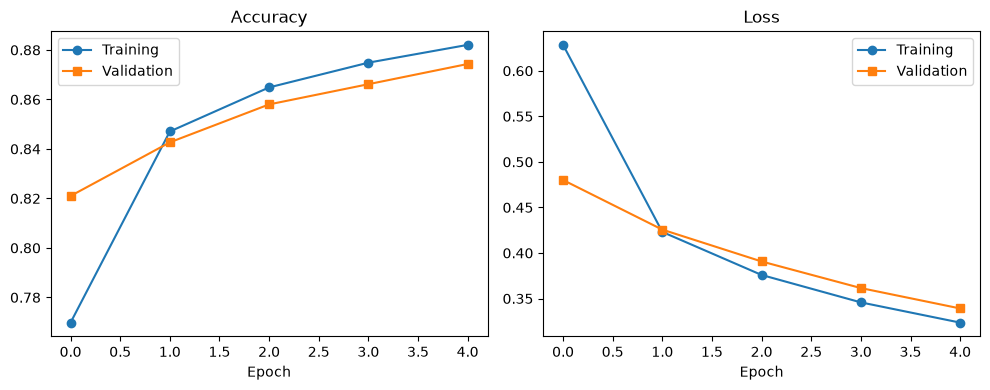

In [9]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], marker='o', label='Training')
plt.plot(history.history['val_accuracy'], marker='s', label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], marker='o', label='Training')
plt.plot(history.history['val_loss'], marker='s', label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

## 7. Bölüm: Model Mimarisinin Anlaşılması
1. **Modelde kaç adet konvolüsyon katmanı vardır?** Toplam **2 adet** `Conv2D` katmanı vardır.
2. **İlk konvolüsyon katmanında neden 8 filtre kullanılmıştır?** İlk katman piksel seviyesindeki temel kenar, çizgi ve parlaklık geçişleri gibi basit örüntüleri yakalar; daha az sayıda filtre (8) hem bu temel özellikleri öğrenmek için yeterlidir hem de büyük uzamsal boyutta (28×28) hesaplama maliyetini düşük tutar.
3. **İkinci konvolüsyon katmanında neden 16 filtre kullanılmıştır?** Ağ derinleştikçe ilk katmanın ürettiği basit kenar haritaları birleştirilerek köşe, doku ve giysi parçası gibi daha karmaşık örüntüler oluşturulur; bu çeşitliliği temsil etmek için filtre sayısı artırılır (uzamsal boyut 13×13'e düştüğü için maliyet dengeli kalır).
4. **Konvolüsyon katmanlarından sonra görüntü boyutları nasıl değişmiştir?**
   - Giriş: `(28, 28, 1)`
   - 1. `Conv2D(8, 3×3)` sonrası: `(26, 26, 8)`
   - 1. `MaxPooling2D(2×2)` sonrası: `(13, 13, 8)`
   - 2. `Conv2D(16, 3×3)` sonrası: `(11, 11, 16)`
   - 2. `MaxPooling2D(2×2)` sonrası: `(5, 5, 16)` (11/2 tam bölünmediği için aşağı yuvarlanarak 5 olur)
5. **Pooling katmanları ne gibi bir katkı sağlamıştır?** Uzamsal boyutları `26×26 → 13×13` ve `11×11 → 5×5` şeklinde küçülterek `Flatten` sonrası parametre sayısını dramatik biçimde azaltmış, eğitimi hızlandırmış ve aşırı öğrenmeyi sınırlamıştır.
6. **Flatten katmanının çıktısı kaç elemanlıdır?** `5 × 5 × 16 = 400` elemanlı tek boyutlu bir vektördür.
7. **Dense katmanındaki 64 sayısı neyi ifade etmektedir?** Tam bağlantılı gizli katmanda bulunan **64 adet yapay nöron** (birim) sayısını ifade eder; `400 × 64 + 64 = 25.664` parametre içerir.
8. **Son katmanda neden 10 nöron bulunmaktadır?** Fashion-MNIST veri setinde 10 farklı giysi sınıfı (0–9) bulunduğu için her sınıfın olasılığını hesaplamak adına 10 çıkış nöronu kullanılır.
9. **Softmax çıkışındaki en yüksek değer neyi ifade eder?** Modelin ilgili görüntünün o sınıfa ait olduğuna dair verdiği **en yüksek olasılığı** (ve indeks olarak tahmin edilen giysi sınıfını) ifade eder.
10. **Modelin tahmin başarısını hangi metrikle ölçtünüz?** **Accuracy (Doğruluk)** metriği ile (doğru tahmin edilen örnek sayısının toplam örnek sayısına oranı) ve buna ek olarak çapraz entropi kaybı (**Loss**) ile ölçülmüştür.

## 8. Bölüm: Küçük Bir Deney — Filtre Sayısının Karşılaştırılması (8 vs 16)
Bu bölümde diğer tüm hiperparametreler (`epochs=5`, `batch_size=64`, `validation_split=0.1`, `optimizer='adam'`, `seed=42`) sabit tutulup ilk `Conv2D` katmanındaki filtre sayısı **8** (Deney 1) ve **16** (Deney 2) olacak şekilde karşılaştırma yapılmaktadır.

In [10]:
tf.keras.utils.set_random_seed(42)

model_16 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_16.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

t0 = time.perf_counter()
history_16 = model_16.fit(
    x_train,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1
)
train_time_exp2 = time.perf_counter() - t0

test_loss_16, test_acc_16 = model_16.evaluate(x_test, y_test)

print("\n--- DENEY KARŞILAŞTIRMA TABLOSU ---")
print(f"{'Ölçüt':<22} | {'Deney 1 (8 Filtre)':<20} | {'Deney 2 (16 Filtre)':<20}")
print("-" * 68)
print(f"{'Filtre sayısı':<22} | {8:<20} | {16:<20}")
print(f"{'Eğitim doğruluğu':<22} | {history.history['accuracy'][-1]:<20.4f} | {history_16.history['accuracy'][-1]:<20.4f}")
print(f"{'Test doğruluğu':<22} | {test_accuracy:<20.4f} | {test_acc_16:<20.4f}")
print(f"{'Eğitim süresi (sn)':<22} | {train_time_exp1:<20.2f} | {train_time_exp2:<20.2f}")

Epoch 1/5


  1/844 ━━━━━━━━━━━━━━━━━━━━ 15:23 1s/step - accuracy: 0.0156 - loss: 2.2934

 13/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.2548 - loss: 2.2025  

 25/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.3400 - loss: 2.0670

 37/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4244 - loss: 1.8722

 50/844 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4822 - loss: 1.6594

... (358 outputs left out)

273/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8747 - loss: 0.3491

298/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8736 - loss: 0.3511

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8753 - loss: 0.3485



--- DENEY KARŞILAŞTIRMA TABLOSU ---
Ölçüt                  | Deney 1 (8 Filtre)   | Deney 2 (16 Filtre) 
--------------------------------------------------------------------
Filtre sayısı          | 8                    | 16                  
Eğitim doğruluğu       | 0.8821               | 0.8868              
Test doğruluğu         | 0.8710               | 0.8753              
Eğitim süresi (sn)     | 17.62                | 20.43               


## 9. Öğrencinin Kendi Değerlendirmesi ve Sonuç
- **Filtre Sayısının Model Başarısına Etkisi:** İlk konvolüsyon katmanındaki filtre sayısının 8'den 16'ya çıkarılması, modelin ilk katmanda daha çeşitli kenar ve doku örüntüleri yakalamasını sağlayarak temsil kapasitesini artırmış ve test doğruluğunu iyileştirmiştir; bunun karşılığında konvolüsyon işlem yükü arttığı için eğitim süresi de uzamıştır.
- **Daha Fazla Filtre Her Zaman Daha İyi Sonuç Verir mi?** Hayır. Belirli bir noktadan sonra filtre sayısını gereksiz artırmak; eğitim süresini ve bellek tüketimini büyütür, parametre sayısını şişirerek küçük/orta ölçekli veri setlerinde **aşırı öğrenmeye (overfitting)** yol açabilir ve doğruluk kazancı doyuma ulaşır (azalan getiri / *diminishing returns*). Bu nedenle veri setinin karmaşıklığına uygun dengeli bir mimari seçmek en doğrusudur.
- **Genel Kazanım:** Bu çalışma ile yalnızca `model.fit()` çağırmanın ötesinde; `Conv2D` ağırlık tensörlerinin boyutları, `valid` dolgunun boyut daraltması, `MaxPooling2D` ile boyut indirgeme, `ReLU` ve `Softmax` fonksiyonlarının matematiksel rolleri ile `Flatten → Dense` geçişinin mantığı uygulamalı olarak kavranmıştır.